# 02. Feature analysis: what really drives churn?

**Question.** Which variables carry the signal, alone and combined, and which ones should the business watch?

**Why it matters.** A variable can look useless on its own and still be decisive once others are controlled. Conversely, a variable can look decisive and simply be a *consequence* of leaving. Both cases change what the operator should do.

Importance below is measured **out-of-fold** (on customers the model did not train on), with grouped CV so identical rows never sit in both train and test.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import mannwhitneyu

from churn.data import load_raw
from churn.explain import out_of_fold_permutation_importance
from churn.features import (
    ALL_FEATURES, BINARY_FEATURES, CATEGORICAL_FEATURES, NUMERIC_FEATURES,
    build_features, duplicate_groups, split_xy,
)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

raw = load_raw()
df = build_features(raw)
X, y = split_xy(df)
groups = duplicate_groups(df).to_numpy()
print(f"raw: {raw.shape} -> modelling table: {df.shape}")
print(f"churn rate: {y.mean():.1%}")

300 fully duplicated rows found (kept, to be reviewed in EDA)


raw: (3150, 14) -> modelling table: (3150, 13)
churn rate: 15.7%


## 1. From 14 columns to 12 features

Decisions taken during the EDA, applied in `src/churn/features.py` (deterministic, so no leakage):

- `age` dropped: only 5 values, a one-to-one recoding of `age_group`.
- `status` and `tariff_plan` (coded 1/2) become clear 0/1 flags `is_inactive` and `is_contract`.
- `charge_amount` (0 to 10, sparse at the top) grouped into `0 / 1 / 2 / 3+`.
- `age_group` kept as a category: its effect is not monotonic.

In [2]:
pd.DataFrame(
    {
        "numeric (log + scaling for linear models)": pd.Series(NUMERIC_FEATURES),
        "binary": pd.Series(BINARY_FEATURES),
        "categorical (one-hot)": pd.Series(CATEGORICAL_FEATURES),
    }
).fillna("")

,numeric (log + scaling for linear models),binary,categorical (one-hot)
0,call_failure,complains,age_group
1,subscription_length,is_inactive,charge_band
2,seconds_of_use,is_contract,
3,frequency_of_use,,
4,frequency_of_sms,,
5,distinct_called_numbers,,
6,customer_value,,


## 2. Alone versus together

Two ways to ask "does this variable matter?":

- **Alone** (*univariate power*): how well does the variable separate churners from non-churners by itself? 0.5 = no separation, 1.0 = perfect. Computed with Mann-Whitney.
- **Together** (*permutation importance*): how much does the tuned gradient boosting lose in PR-AUC when this variable is shuffled?

Two versions of the model are shown. The **early-warning** version drops `complains` and `is_inactive`, which may be consequences of leaving (the dataset does not say when they were measured).

*Univariate power is computed for numeric variables only (Mann-Whitney). For binary and categorical variables, the association with churn is shown in notebook 01 (Cramér's V). That is why some cells are empty.*

In [3]:
uni = {}
for c in NUMERIC_FEATURES:
    u, _ = mannwhitneyu(X.loc[y == 1, c], X.loc[y == 0, c])
    auc = u / ((y == 1).sum() * (y == 0).sum())
    uni[c] = max(auc, 1 - auc)
uni = pd.Series(uni, name="univariate_power")

imp_full = out_of_fold_permutation_importance(X, y, groups).set_index("feature")["pr_auc_drop"]
imp_early = out_of_fold_permutation_importance(
    X.drop(columns=["complains", "is_inactive"]), y, groups
).set_index("feature")["pr_auc_drop"]

table = pd.concat(
    [uni, imp_full.rename("importance_full"), imp_early.rename("importance_early_warning")], axis=1
).sort_values("importance_full", ascending=False)
table.round(3)

,univariate_power,importance_full,importance_early_warning
frequency_of_use,0.772,0.267,0.353
complains,NaN,0.204,NaN
subscription_length,0.527,0.120,0.233
call_failure,0.525,0.115,0.268
seconds_of_use,0.791,0.111,0.241
is_inactive,NaN,0.089,NaN
age_group,NaN,0.057,0.098
distinct_called_numbers,0.739,0.055,0.114
frequency_of_sms,0.677,0.010,0.038
customer_value,0.786,0.010,0.031


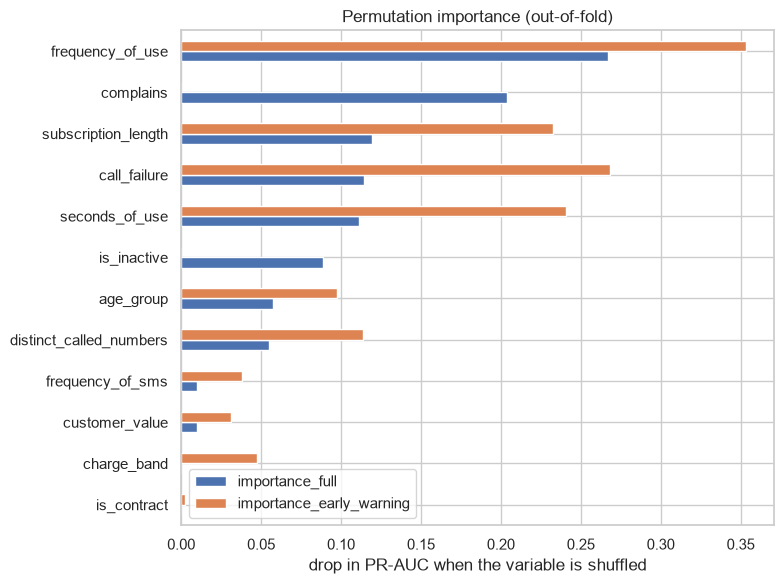

In [4]:
plot_df = table[["importance_full", "importance_early_warning"]].sort_values("importance_full")
plot_df.plot.barh(figsize=(8, 6))
plt.xlabel("drop in PR-AUC when the variable is shuffled")
plt.title("Permutation importance (out-of-fold)")
plt.tight_layout()
plt.savefig("../reports/figures/permutation_importance.png", dpi=150)
plt.show()

**How to read this.**

- **Usage dominates.** `frequency_of_use` is the top variable in both versions, and `seconds_of_use` and `customer_value` are the best single separators. Customers who use the service less are the ones who leave. Because these usage variables are strongly correlated, the ranking among them should not be over-interpreted.
- **`call_failure` and `subscription_length` are the surprise.** Alone they barely separate churners (univariate power close to 0.5), yet they weigh heavily once usage is controlled. `call_failure` is correlated with usage (about 0.5), so its effect is probably only visible *conditionally*; this is a plausible reading, not something these data prove. Dropping them because of a univariate test, as the academic version suggested, would have thrown away real signal.
- **`complains` matters, `is_inactive` less than expected.** Part of the inactivity signal is already contained in usage.
- **`charge_band` is useless in the full model but useful in the early-warning one** (0.048), where it partly substitutes for the removed variables.
- **Caution.** Usage variables are strongly correlated (up to 0.94), so permutation importance is shared between them: read values as orders of magnitude. Importance means "helps predict", not "causes churn".

## 3. Who churns: complaints and inactivity combined

In [5]:
seg = df.assign(churn=y).pivot_table(
    index="complains", columns="is_inactive", values="churn", aggfunc=["mean", "size", "sum"]
)
seg.columns = [f"{a}_{'inactive' if b else 'active'}" for a, b in seg.columns]
seg.rename(columns={"mean_active": "churn_rate_active", "mean_inactive": "churn_rate_inactive",
                    "size_active": "n_active", "size_inactive": "n_inactive",
                    "sum_active": "churners_active", "sum_inactive": "churners_inactive"}).round(3)

,churn_rate_active,churn_rate_inactive,n_active,n_inactive,churners_active,churners_inactive
complains,,,,,,
0,0.029,0.367,2285,624,66,229
1,0.711,0.892,83,158,59,141


Active customers who did not complain are the hardest to spot: they still contain 66 churners among 2,285 customers (2.9%), more than the 59 churners among active complainers. A rule such as "contact those who complain" would miss most departures, which is why the model must rely on usage.

## 4. The business angle: how much value leaves?

In [6]:
value = raw.groupby("churn")["customer_value"].agg(["count", "sum", "mean", "median"]).round(1)
value["share_of_total_value"] = (value["sum"] / value["sum"].sum()).round(3)
value

,count,sum,mean,median,share_of_total_value
churn,,,,,
0,2655,1421783.0,535.5,268.1,0.958
1,495,61781.6,124.8,96.8,0.042


## Conclusions

1. Usage is the strongest behavioural signal, and it is observable without any complaint.
2. Variables that look weak alone (`call_failure`, `subscription_length`) matter in combination: never filter variables on univariate tests only.
3. `complains` and `is_inactive` are strong but possibly late signals: hence two model versions.
4. Churners are a small share of total customer value, so retention offers must stay cheap. This is what the decision layer (notebook 03 and `evaluate.py`) quantifies.

Association is not causation: recommendations such as improving network quality need A/B tests.